# ДЗ 1. Анализ продаж товара

Анализируем продажи товара **20725, LUNCH BAG RED RETROSPOT**, который отличается от товара 85123A из лекции.
Считаем проданные штуки по всем странам без отмен и возвратов, затем проверяем качество данных, сезонность и стационарность.
Источник: [Online Retail, UCI](https://doi.org/10.24432/C5BW33), Chen (2015), CC BY 4.0; функции находятся в `analysis_utils.py`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import analysis_utils as au

plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid': True,
                     'grid.alpha': 0.25, 'font.family': 'DejaVu Sans'})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.3f}'.format)
ROOT = au.ROOT
for folder in ['data/processed', 'results', 'figures']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
print('Папка проекта:', ROOT.name)

Папка проекта: retail_homework


## 1. Загрузка и структура

In [2]:
df, source_hash = au.load_data()
print('Размер:', df.shape)
print('Период:', df.InvoiceDate.min(), '/', df.InvoiceDate.max())
display(df.head())
display(pd.DataFrame({'Тип': df.dtypes.astype(str), 'Пропуски': df.isna().sum()}))

Размер: (541909, 8)
Период: 2010-12-01 08:26:00 / 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.550,17850.000,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.390,17850.000,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.750,17850.000,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.390,17850.000,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.390,17850.000,United Kingdom


,Тип,Пропуски
InvoiceNo,str,0
StockCode,str,0
Description,object,1454
Quantity,int64,0
InvoiceDate,datetime64[us],0
UnitPrice,float64,0
CustomerID,float64,135080
Country,str,0


In [3]:
product, sales, quality, coverage, series = au.prepare_series(df)
display(product.Description.value_counts().rename('Строк'))
display(quality.to_frame())
display(sales[['InvoiceNo', 'InvoiceDate', 'Quantity', 'UnitPrice']].head())
quality.to_csv(ROOT / 'results/data_quality.csv')

Description
LUNCH BAG RED RETROSPOT    1638
LUNCH BAG RED SPOTTY          1
Name: Строк, dtype: int64

,Количество
Строк товара,1639
Отмены,44
Количество <= 0,44
Цена <= 0,0
Нет даты,0
Нет количества,0
Нет CustomerID,280
Полные дубликаты,13
Строк после фильтрации,1595


,InvoiceNo,InvoiceDate,Quantity,UnitPrice
93,536378,2010-12-01 09:37:00,10,1.650
368,536401,2010-12-01 11:21:00,1,1.650
614,536412,2010-12-01 11:49:00,1,1.650
1869,536544,2010-12-01 14:32:00,4,4.210
2325,536577,2010-12-01 16:13:00,60,1.450


Товар выбираем по StockCode, исключаем отмены и строки с неположительным количеством или ценой.
Строки без CustomerID сохраняем: для суммарных продаж он не нужен.
Полные дубликаты оставляем, поскольку без ID позиции нельзя отличить повтор записи от отдельной покупки.

In [4]:
unique_sales = sales.drop_duplicates()
duplicate_units = sales.Quantity.sum() - unique_sales.Quantity.sum()
print('Количество в совпадающих строках:', int(duplicate_units))
print('Доля от продаж товара: {:.2%}'.format(duplicate_units / sales.Quantity.sum()))
first_month = sales[sales.InvoiceDate < '2011-01-01']
print('Строк:', len(first_month), '| Штук:', int(first_month.Quantity.sum()))

Количество в совпадающих строках: 121
Доля от продаж товара: 0.62%
Строк: 88 | Штук: 732


## 2. Календарь и пропуски

Отдельно проверяем дни без продаж товара и дни без любых транзакций магазина.
Считая выгрузку полным журналом, ставим ноль при отсутствии зарегистрированных продаж; это не оценка скрытого спроса, а сбои выгрузки исключить нельзя.
Пропуски обязательных полей проверяем до агрегации и нулями не заменяем.

In [5]:
display(coverage.groupby('status').agg(Дней=('sales', 'size'), Штук=('sales', 'sum')))
no_shop = coverage.loc[coverage.all_transactions.eq(0)]
print(', '.join(no_shop.index.strftime('%Y-%m-%d')))
display(coverage.groupby(coverage.index.day_of_week)['all_transactions'].agg(['count', 'sum']))
coverage.to_csv(ROOT / 'results/calendar_audit.csv')

,Дней,Штук
status,,
Есть продажи товара,298,19553.000
Нет продаж товара,7,0.000
Нет транзакций магазина,69,0.000


2010-12-04, 2010-12-11, 2010-12-18, 2010-12-24, 2010-12-25, 2010-12-26, 2010-12-27, 2010-12-28, 2010-12-29, 2010-12-30, 2010-12-31, 2011-01-01, 2011-01-02, 2011-01-03, 2011-01-08, 2011-01-15, 2011-01-22, 2011-01-29, 2011-02-05, 2011-02-12, 2011-02-19, 2011-02-26, 2011-03-05, 2011-03-12, 2011-03-19, 2011-03-26, 2011-04-02, 2011-04-09, 2011-04-16, 2011-04-22, 2011-04-23, 2011-04-24, 2011-04-25, 2011-04-29, 2011-04-30, 2011-05-02, 2011-05-07, 2011-05-14, 2011-05-21, 2011-05-28, 2011-05-30, 2011-06-04, 2011-06-11, 2011-06-18, 2011-06-25, 2011-07-02, 2011-07-09, 2011-07-16, 2011-07-23, 2011-07-30, 2011-08-06, 2011-08-13, 2011-08-20, 2011-08-27, 2011-08-29, 2011-09-03, 2011-09-10, 2011-09-17, 2011-09-24, 2011-10-01, 2011-10-08, 2011-10-15, 2011-10-22, 2011-10-29, 2011-11-05, 2011-11-12, 2011-11-19, 2011-11-26, 2011-12-03


,count,sum
date,,
0,53,95111
1,53,101808
2,54,94565
3,54,103857
4,54,82193
5,53,0
6,53,64375


## 3. Дневная, недельная и месячная агрегации

Исключаем неполный день 09.12.2011 и неполные крайние недели и месяцы.
Неделя идет с понедельника по воскресенье и имеет метку воскресенья, месяц имеет метку первого дня.
Месячная сумма известна только после окончания месяца, а диапазоны трех рядов немного различаются.

In [6]:
summary = au.describe_series(series)
display(summary)
for frequency, y in series.items():
    assert y.index.is_monotonic_increasing and y.index.is_unique
    assert y.notna().all() and (y >= 0).all()
    assert y.index.equals(pd.date_range(y.index[0], y.index[-1], freq=au.FREQUENCIES[frequency]))
summary.to_csv(ROOT / 'results/series_summary.csv')

,Начало,Конец,Длина,Пропуски,Нули,Среднее,Медиана,Станд. отклонение,Минимум,Максимум,CV,Доля нулей
Частота,,,,,,,,,,,,
День,2010-12-01,2011-12-08,373,0,76,52.308,36.000,62.346,0.000,432.000,1.192,0.204
Неделя,2010-12-12,2011-12-04,52,0,1,366.750,326.000,180.009,0.000,885.000,0.491,0.019
Месяц,2010-12-01,2011-11-01,12,0,0,1596.333,1613.000,460.607,732.000,2355.000,0.289,0.000


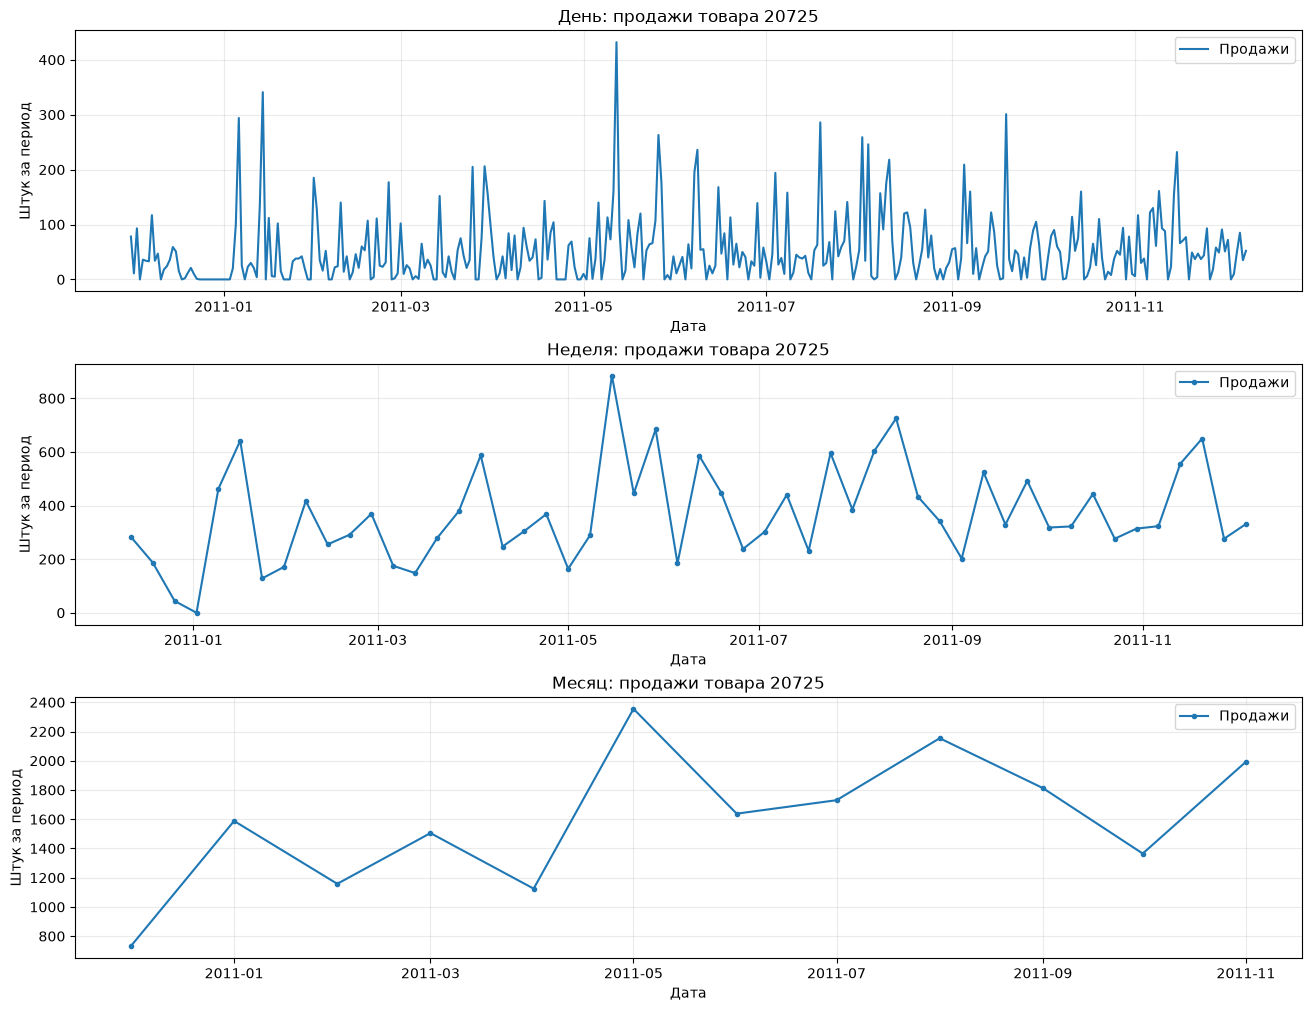

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), layout='constrained')
for ax, (frequency, y) in zip(axes, series.items()):
    ax.plot(y.index, y, marker='.' if frequency != 'День' else None, label='Продажи')
    ax.set(title=f'{frequency}: продажи товара 20725', xlabel='Дата', ylabel='Штук за период')
    ax.legend()
fig.savefig(ROOT / 'figures/01_series.png', dpi=150)
plt.show()

Агрегация сглаживает дневные колебания, но меняет масштаб продаж.
Сравнивать среднее число штук за день со средним числом штук за месяц напрямую нельзя.
CV и доля нулей показывают относительную изменчивость и прерывистость продаж.

## 4. Выбросы и изменение уровня

Отмечаем выбросы по порогу Q3 + 1.5 IQR, рассчитанному до всех дневных тестовых окон.
Крупные значения сохраняем: они могут быть реальными оптовыми заказами.
Полный ряд показываем для описания, а сезонность и стационарность исследуем на обучающем участке.

In [8]:
y = series['День']
analysis_end = len(y) - 61 - 14
train = y.iloc[:analysis_end]
outliers = au.outlier_table(y, train)
print('Анализируем начало ряда до:', train.index[-1].date())
print('Потенциальных выбросов:', len(outliers))
display(outliers)
outliers.to_csv(ROOT / 'results/outliers.csv')

Анализируем начало ряда до: 2011-09-24
Потенциальных выбросов: 25


,sales,threshold
date,,
2011-01-06,294.000,159.000
2011-01-14,341.000,159.000
2011-01-31,185.000,159.000
2011-02-25,177.000,159.000
2011-03-25,205.000,159.000
2011-03-29,206.000,159.000
2011-05-11,160.000,159.000
2011-05-12,432.000,159.000
2011-05-26,263.000,159.000


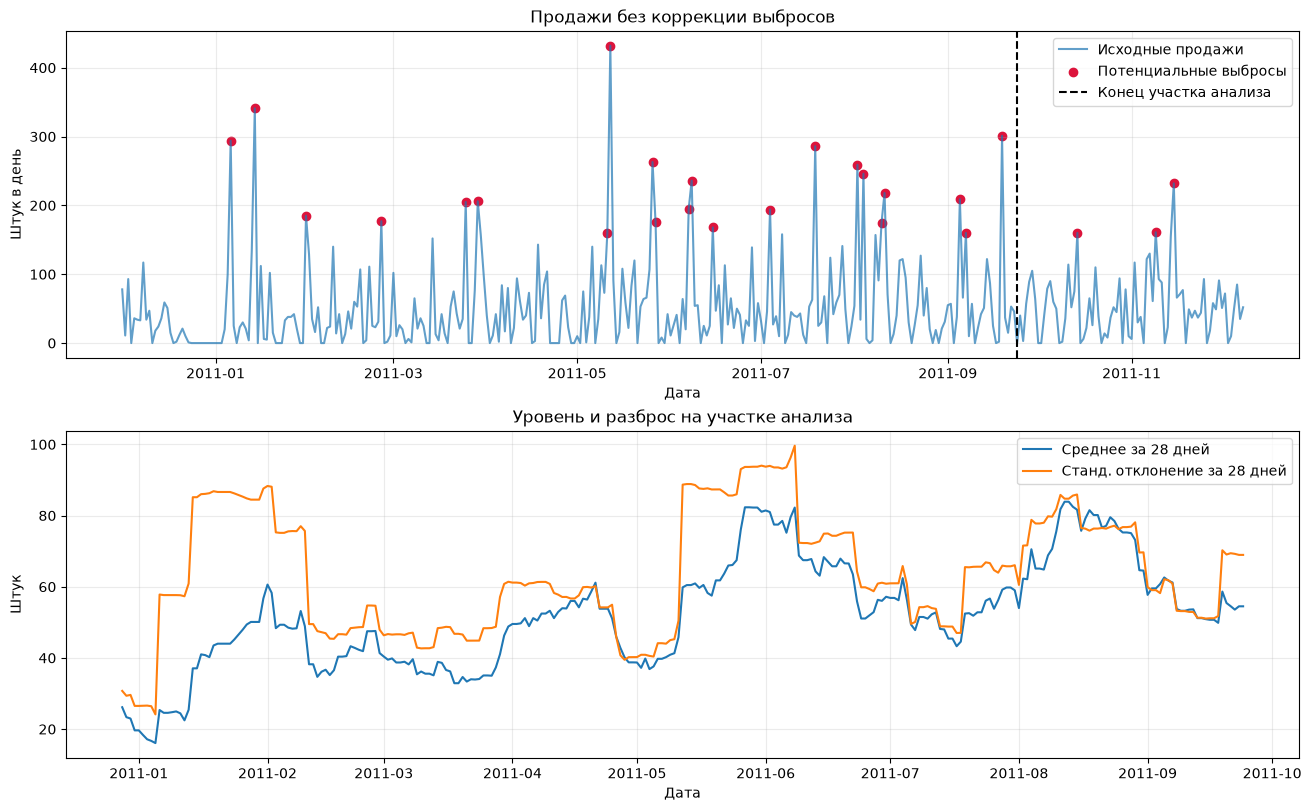

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), layout='constrained')
axes[0].plot(y.index, y, label='Исходные продажи', alpha=0.7)
axes[0].scatter(outliers.index, outliers.sales, color='crimson', label='Потенциальные выбросы')
axes[0].axvline(train.index[-1], color='black', ls='--', label='Конец участка анализа')
axes[0].set(title='Продажи без коррекции выбросов', xlabel='Дата', ylabel='Штук в день')
axes[0].legend()
axes[1].plot(train.index, train.rolling(28).mean(), label='Среднее за 28 дней')
axes[1].plot(train.index, train.rolling(28).std(), label='Станд. отклонение за 28 дней')
axes[1].set(title='Уровень и разброс на участке анализа', xlabel='Дата', ylabel='Штук')
axes[1].legend()
fig.savefig(ROOT / 'figures/02_outliers_rolling.png', dpi=150)
plt.show()

In [10]:
peak_dates = outliers.nlargest(5, 'sales').index
peak_orders = sales[sales.InvoiceDate.dt.normalize().isin(peak_dates)]
peak_summary = peak_orders.groupby(peak_orders.InvoiceDate.dt.normalize()).agg(
    Штук=('Quantity', 'sum'), Строк=('Quantity', 'size'),
    Заказов=('InvoiceNo', 'nunique'), Крупнейшая_позиция=('Quantity', 'max'))
display(peak_summary)
print('До и после диагностики значения совпадают:', y.equals(series['День']))

,Штук,Строк,Заказов,Крупнейшая_позиция
InvoiceDate,,,,
2011-01-06,294,10,10,100
2011-01-14,341,7,7,200
2011-05-12,432,9,9,200
2011-07-19,286,11,11,100
2011-09-19,301,10,10,200


До и после диагностики значения совпадают: True


## 5. Декомпозиция и сезонность

Робастная STL с периодом 7 выделяет тренд, недельную компоненту и остаток, сохраняя исходные продажи.
Недельный эффект проверяем по профилю дней, ACF, периодограмме и силе сезонности max(0, 1 - Var(остаток) / Var(остаток + сезонность)).
Сила сезонности не является p-value, а для проверки годового цикла истории недостаточно.

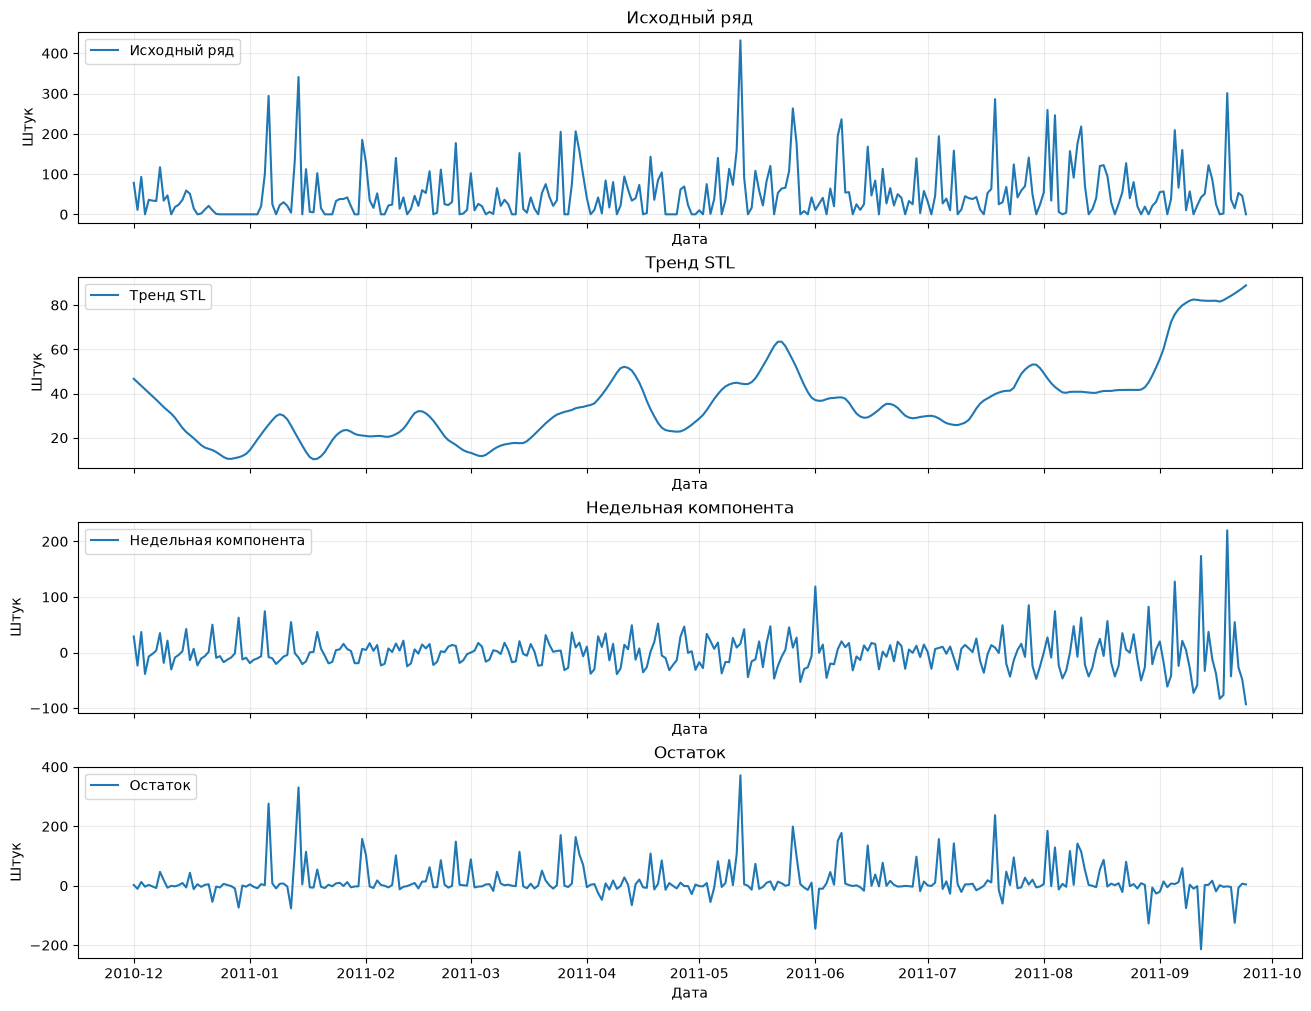

Сила недельной сезонности: 0.184
ACF(7): 0.154; ACF(14): 0.192


In [11]:
fit, strength, correlations, frequencies, power = au.seasonal_diagnostics(train)
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True, layout='constrained')
for ax, component, title in zip(axes, [train, fit.trend, fit.seasonal, fit.resid],
                               ['Исходный ряд', 'Тренд STL', 'Недельная компонента', 'Остаток']):
    ax.plot(train.index, component, label=title)
    ax.set(title=title, ylabel='Штук', xlabel='Дата')
    ax.legend(loc='upper left')
fig.savefig(ROOT / 'figures/03_stl.png', dpi=150)
plt.show()
print(f'Сила недельной сезонности: {strength:.3f}')
print(f'ACF(7): {correlations[7]:.3f}; ACF(14): {correlations[14]:.3f}')

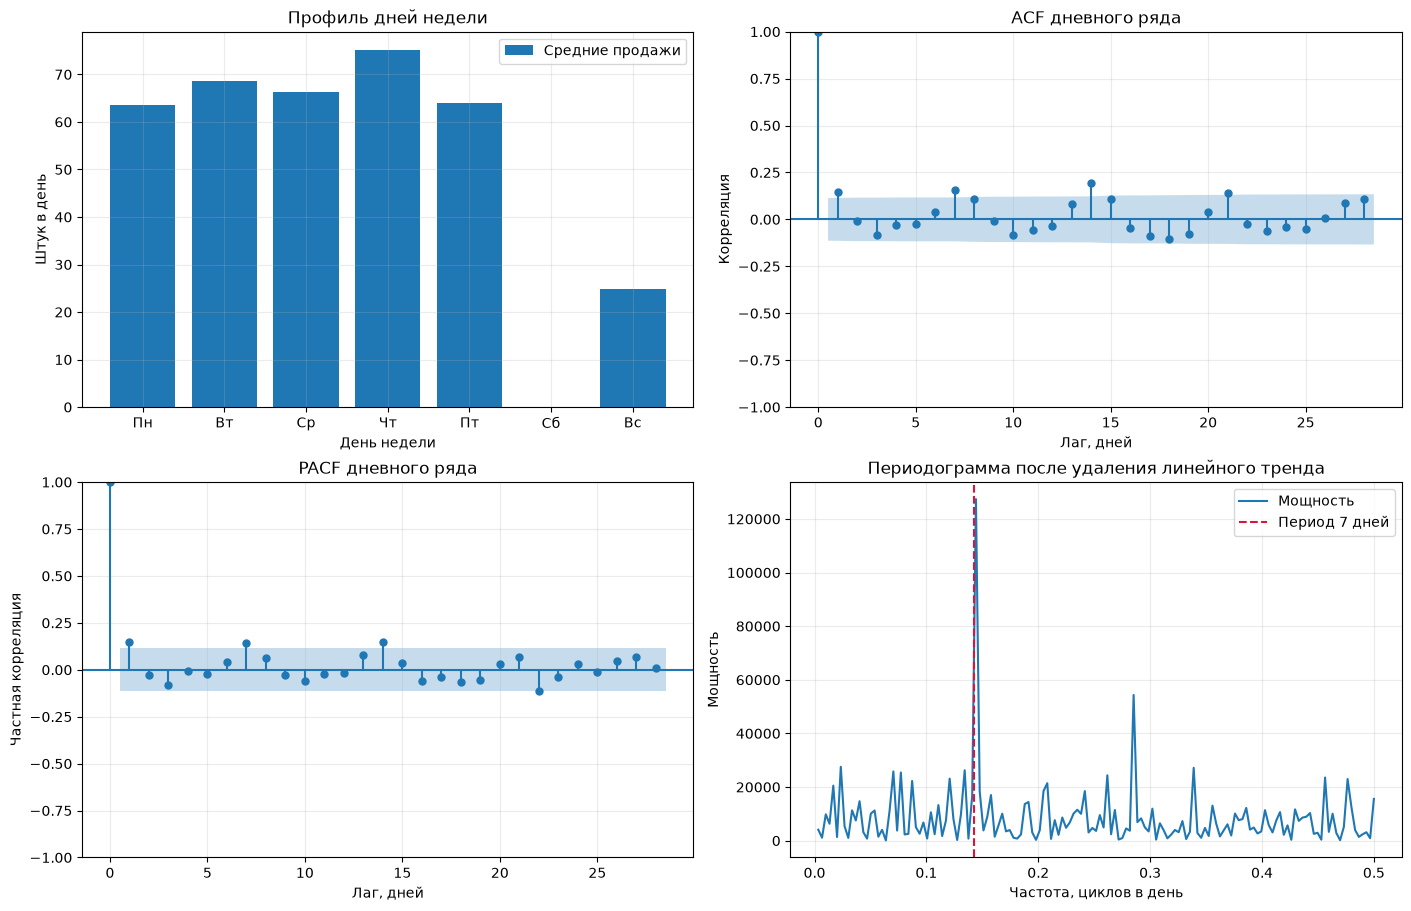

In [12]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 2, figsize=(14, 9), layout='constrained')
weekday = train.groupby(train.index.day_of_week).mean().reindex(range(7))
axes[0, 0].bar(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'], weekday, label='Средние продажи')
axes[0, 0].set(title='Профиль дней недели', xlabel='День недели', ylabel='Штук в день')
axes[0, 0].legend()
plot_acf(train, lags=28, ax=axes[0, 1], title='ACF дневного ряда')
axes[0, 1].set(xlabel='Лаг, дней', ylabel='Корреляция')
plot_pacf(train, lags=28, ax=axes[1, 0], method='ywm', title='PACF дневного ряда')
axes[1, 0].set(xlabel='Лаг, дней', ylabel='Частная корреляция')
axes[1, 1].plot(frequencies[1:], power[1:], label='Мощность')
axes[1, 1].axvline(1 / 7, color='crimson', ls='--', label='Период 7 дней')
axes[1, 1].set(title='Периодограмма после удаления линейного тренда',
               xlabel='Частота, циклов в день', ylabel='Мощность')
axes[1, 1].legend()
fig.savefig(ROOT / 'figures/04_seasonality.png', dpi=150)
plt.show()

In [13]:
# Сравниваем профиль на двух частях обучающего участка.
mid = len(train) // 2
profiles = pd.DataFrame({
    'Первая половина': train.iloc[:mid].groupby(train.iloc[:mid].index.day_of_week).mean(),
    'Вторая половина': train.iloc[mid:].groupby(train.iloc[mid:].index.day_of_week).mean()})
profiles.index = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
display(profiles)
seasonal_info = {'strength': float(strength), 'acf7': float(correlations[7]),
                'acf14': float(correlations[14]),
                'trend_start': float(fit.trend.iloc[:28].mean()),
                'trend_end': float(fit.trend.iloc[-28:].mean()),
                'residual_sd': float(fit.resid.std())}
_ = (ROOT / 'results/seasonality.json').write_text(json.dumps(seasonal_info, indent=2), encoding='utf-8')

,Первая половина,Вторая половина
Пн,52.238,74.762
Вт,45.857,91.571
Ср,56.864,76.238
Чт,50.727,100.905
Пт,65.524,62.682
Сб,0.000,0.000
Вс,14.524,35.238


Сила недельной сезонности равна 0.184, ACF(7) = 0.154: недельный эффект есть, но он умеренный.
Средняя трендовая компонента выросла с 25.7 до 74.8 штук между первыми и последними 28 днями участка анализа.
Крупные остатки показывают, что недельный цикл не объясняет все колебания продаж.

## 6. Стационарность

При p < 0.05 ADF отвергает единичный корень, а KPSS отвергает стационарность относительно постоянного уровня.
На обучающих данных сравниваем исходные ряды и первые разности, для дней также проверяем разность с лагом 7.
Противоречие тестов трактуем как неопределенность; 8 месячных точек для надежного вывода недостаточно.

In [14]:
weekly_train = series['Неделя'].iloc[:len(series['Неделя']) - 8 - 2]
variants = {'День: исходный': train, 'День: разность 1': train.diff().dropna(),
            'День: разность 7': train.diff(7).dropna(), 'Неделя: исходный': weekly_train,
            'Неделя: разность 1': weekly_train.diff().dropna()}
tests = pd.DataFrame([au.stationarity_tests(s, name) for name, s in variants.items()])
test_display = tests.drop(columns='Примечание').copy()
for column in ['ADF p', 'KPSS p']:
    test_display[column] = test_display[column].map('{:.3g}'.format)
display(test_display)
# Для KPSS p = 0.1 означает, что фактическое p выше.
tests.to_csv(ROOT / 'results/stationarity.csv', index=False)

,Ряд,n,ADF,ADF p,KPSS,KPSS p
0,День: исходный,298,-14.796,2.14e-27,0.662,0.017
1,День: разность 1,297,-9.099,3.66e-15,0.115,0.1
2,День: разность 7,291,-5.493,2.16e-06,0.013,0.1
3,Неделя: исходный,42,-5.454,2.61e-06,0.612,0.0216
4,Неделя: разность 1,41,-9.943,2.64e-17,0.500,0.0417


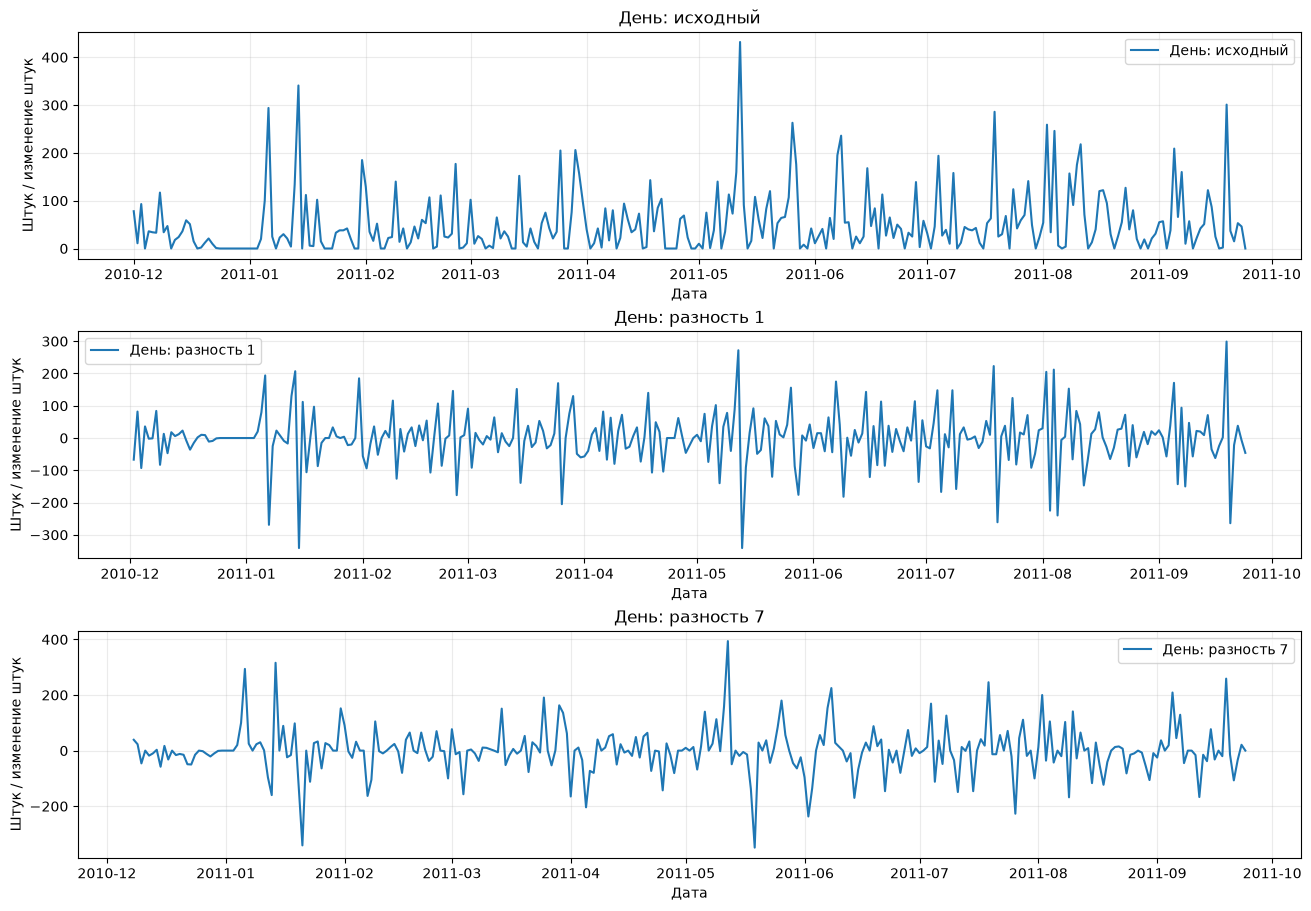

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), layout='constrained')
for ax, (name, values) in zip(axes, list(variants.items())[:3]):
    ax.plot(values.index, values, label=name)
    ax.set(title=name, xlabel='Дата', ylabel='Штук / изменение штук')
    ax.legend()
fig.savefig(ROOT / 'figures/05_stationarity.png', dpi=150)
plt.show()

ADF отвергает единичный корень дневного ряда, но KPSS p = 0.017 указывает на изменение уровня.
После первых и сезонных разностей оба теста согласуются со стационарностью, поэтому для ARIMA используем первые разности.
Для недельных разностей KPSS p = 0.042: согласия тестов нет, а короткая история ограничивает надежность вывода.

## 7. Сохранение и выводы

Сохраняем дневной, недельный и месячный ряды в исходных единицах продаж.
Крупные значения оставляем, поскольку они могут отражать реальные оптовые заказы.
Разности и компоненты STL используем только для анализа, исходные ряды ими не заменяем.

In [16]:
au.save_series(series)
metadata = {'stock_code': au.STOCK_CODE, 'product': au.PRODUCT_NAME,
            'source': au.SOURCE_URL, 'sha256_xlsx': source_hash,
            'analysis_end': str(train.index[-1].date()),
            'target': 'Количество проданных штук, все страны, без отмен и возвратов',
            'zero_assumption': 'Нет зарегистрированных продаж в полном журнале транзакций',
            'duplicates': 'Сохранены: нет уникального идентификатора позиции'}
_ = (ROOT / 'data/processed/metadata.json').write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')

### Интерпретация результатов

Пропусков дат и количества у товара нет, а 25 потенциальных выбросов сохранены как возможные оптовые заказы.
Недельный эффект умеренный: сила сезонности 0.184 и ACF(7) = 0.154, при этом агрегация снижает CV с 1.19 для дней до 0.29 для месяцев.
Для дневных разностей тесты согласуются со стационарностью, для недельных согласия нет (KPSS p = 0.042); сохраняем продажи в исходной шкале.